# Vision — Analisis Kesalahan (gambar mana yang salah, dan kenapa?)
**Kapan dipakai:** **setelah** model jadi, untuk bahan perbaikan (augmentasi, data tambahan)
dan slide presentasi.

**Langkah:** prediksi out-of-fold (tiap gambar train punya tebakan "jujur") → lihat:
- kelas mana yang tertukar;
- gambar "yakin tapi salah" (curiga label salah) dan gambar paling ragu;
- irisan gambar (gelap/terang, kontras rendah) yang paling sering salah.

**Data demo:** CIFAR-10 kecil, embedding CLIP + LogisticRegression.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import CLIPModel, CLIPProcessor

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/classification/cifar10_small"  # GANTI
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
CLIP_FOLDER = "../../pretrained/clip_b32"

PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
TARGET = "label"
N_EXAMPLES = 16       # gambar yang ditampilkan di tiap grid
BATCH_SIZE = 32
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
print(train.shape)
print(train[TARGET].value_counts())

(4000, 2)
label
airplane      400
automobile    400
bird          400
cat           400
deer          400
dog           400
frog          400
horse         400
ship          400
truck         400
Name: count, dtype: int64


## Embedding CLIP + ukuran sederhana tiap gambar (kecerahan, kontras)

In [4]:
clip = CLIPModel.from_pretrained(CLIP_FOLDER, local_files_only=True)
clip = clip.to(DEVICE)
clip.eval()
processor = CLIPProcessor.from_pretrained(CLIP_FOLDER, local_files_only=True)

batches = []
brightness = []
contrast = []
for start in range(0, len(train), BATCH_SIZE):
    images = []
    for path in train[PATH_COL][start:start + BATCH_SIZE]:
        image = Image.open(f"{DATA_FOLDER}/{path}").convert("RGB")
        gray = np.asarray(image.convert("L"), dtype=float)
        brightness.append(gray.mean())
        contrast.append(gray.std())
        images.append(image)
    encoded = processor(images=images, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        output = clip.get_image_features(**encoded)
    batches.append(output.pooler_output.cpu().numpy())
X = np.concatenate(batches)
train["kecerahan"] = brightness
train["kontras"] = contrast

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Prediksi out-of-fold (tiap gambar ditebak model yang tidak melihatnya)

In [5]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
proba = cross_val_predict(model, X, train[TARGET], cv=folds, method="predict_proba")
classes = np.array(sorted(train[TARGET].unique()))
train["tebakan"] = classes[proba.argmax(axis=1)]
train["yakin"] = proba.max(axis=1)
train["salah"] = train["tebakan"] != train[TARGET]
print(classification_report(train[TARGET], train["tebakan"]))

              precision    recall  f1-score   support

    airplane       0.96      0.95      0.96       400
  automobile       0.97      0.96      0.96       400
        bird       0.91      0.89      0.90       400
         cat       0.84      0.85      0.84       400
        deer       0.88      0.89      0.88       400
         dog       0.90      0.89      0.89       400
        frog       0.90      0.93      0.91       400
       horse       0.93      0.93      0.93       400
        ship       0.99      0.97      0.98       400
       truck       0.96      0.96      0.96       400

    accuracy                           0.92      4000
   macro avg       0.92      0.92      0.92      4000
weighted avg       0.92      0.92      0.92      4000



## Kelas mana yang tertukar?

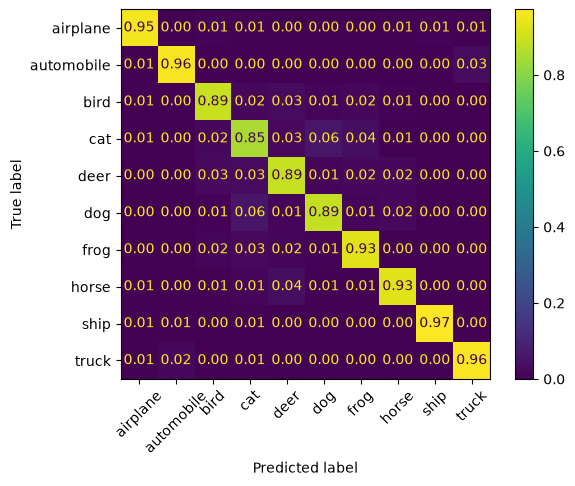

pasangan paling sering tertukar (label asli, tebakan):
label       tebakan
cat         dog        23
dog         cat        23
horse       deer       15
cat         frog       15
automobile  truck      12
deer        cat        12
bird        deer       11
frog        cat        10
deer        bird       10
cat         deer       10
dtype: int64


In [6]:
ConfusionMatrixDisplay.from_predictions(train[TARGET], train["tebakan"], xticks_rotation=45,
                                        normalize="true", values_format=".2f")
plt.savefig("confusion.png", dpi=150, bbox_inches="tight")
plt.show()

wrong = train[train["salah"]]
pair_counts = wrong.groupby([TARGET, "tebakan"]).size()
pair_counts = pair_counts.sort_values(ascending=False)
print("pasangan paling sering tertukar (label asli, tebakan):")
print(pair_counts.head(10))

## Yakin tapi salah (curiga label salah) dan paling ragu

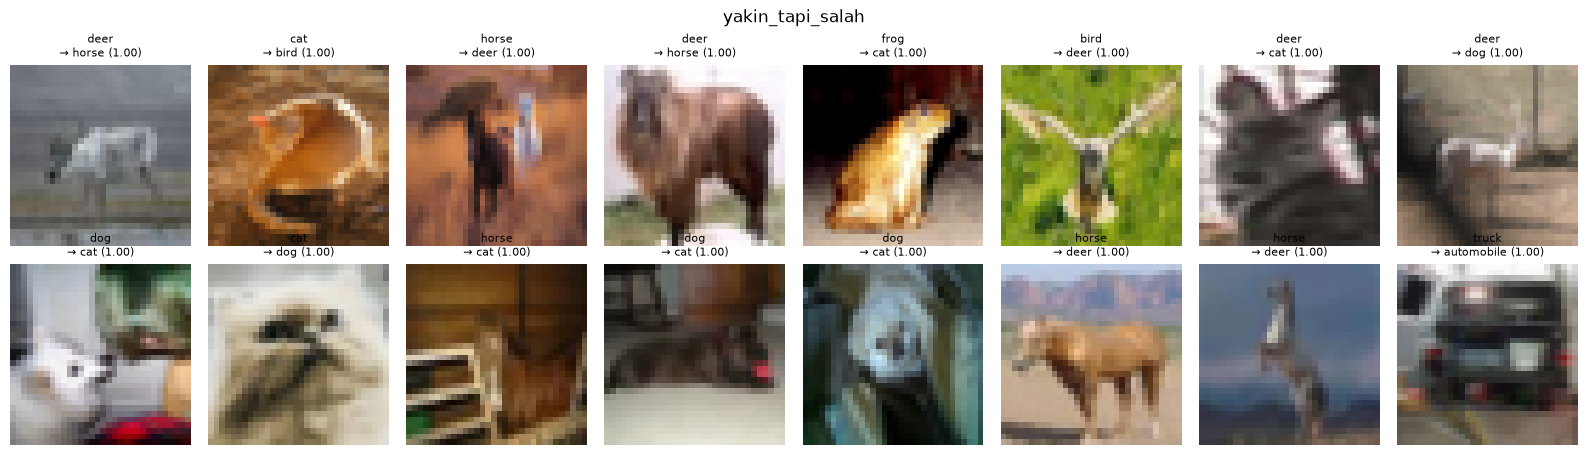

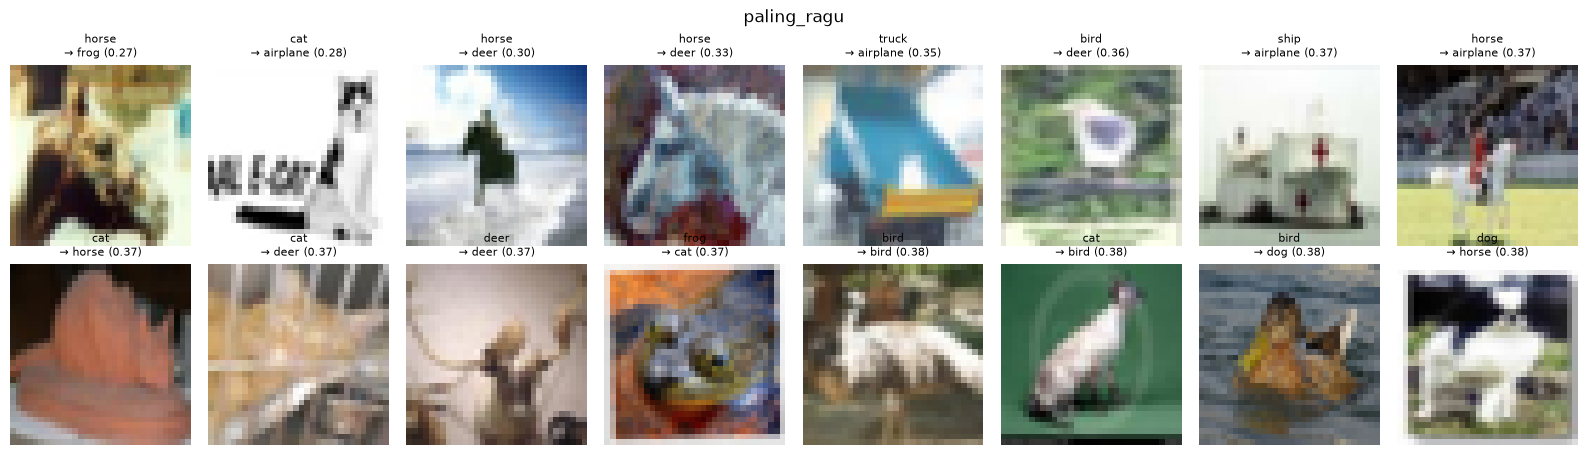

In [7]:
confident_wrong = wrong.sort_values("yakin", ascending=False).head(N_EXAMPLES)
unsure = train.sort_values("yakin").head(N_EXAMPLES)

for title, table in [("yakin_tapi_salah", confident_wrong), ("paling_ragu", unsure)]:
    fig, axes = plt.subplots(2, N_EXAMPLES // 2, figsize=(16, 4.6))
    for ax, path, label, guess, confidence in zip(axes.ravel(), table[PATH_COL], table[TARGET],
                                                   table["tebakan"], table["yakin"]):
        ax.imshow(Image.open(f"{DATA_FOLDER}/{path}"))
        ax.set_title(f"{label}\n→ {guess} ({confidence:.2f})", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=150)
    plt.show()

## Irisan: apakah gambar gelap / kontras rendah lebih sering salah?
`pd.qcut` membagi gambar jadi 5 kelompok sama banyak, dari paling gelap ke paling terang.

In [8]:
train["kelompok_kecerahan"] = pd.qcut(train["kecerahan"], 5)
train["kelompok_kontras"] = pd.qcut(train["kontras"], 5)
error_by_brightness = train.groupby("kelompok_kecerahan", observed=True)["salah"].mean()
error_by_contrast = train.groupby("kelompok_kontras", observed=True)["salah"].mean()
print(error_by_brightness.round(3))
print(error_by_contrast.round(3))
print("rata-rata kesalahan:", round(train["salah"].mean(), 3))

kelompok_kecerahan
(21.0, 97.449]        0.090
(97.449, 114.233]     0.081
(114.233, 128.391]    0.082
(128.391, 146.586]    0.072
(146.586, 252.166]    0.066
Name: salah, dtype: float64
kelompok_kontras
(7.242, 36.912]      0.091
(36.912, 45.912]     0.080
(45.912, 53.856]     0.070
(53.856, 62.872]     0.072
(62.872, 102.825]    0.079
Name: salah, dtype: float64
rata-rata kesalahan: 0.078


## Ringkasan per kelas (untuk slide)

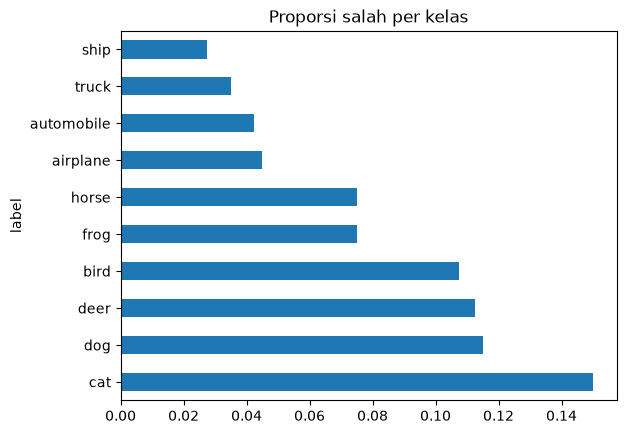

In [9]:
error_by_class = train.groupby(TARGET)["salah"].mean()
error_by_class = error_by_class.sort_values(ascending=False)
error_by_class.plot.barh(title="Proporsi salah per kelas")
plt.savefig("salah_per_kelas.png", dpi=150, bbox_inches="tight")
plt.show()
train[[PATH_COL, TARGET, "tebakan", "yakin", "salah"]].to_csv("oof.csv", index=False)